# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

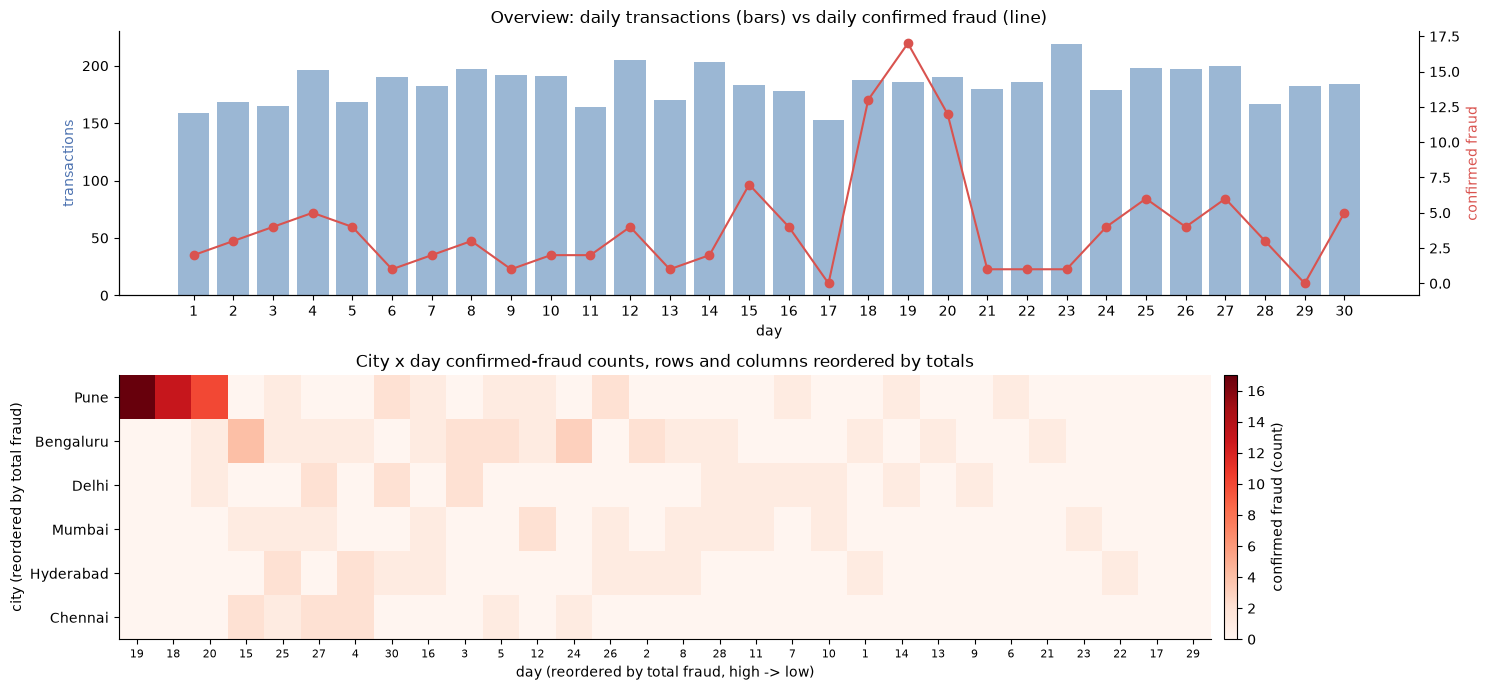

Cells with the most confirmed fraud:
     city  day  fraud
     Pune   19     17
     Pune   18     13
     Pune   20     10
Bengaluru   15      4
Bengaluru   24      3
Bengaluru    3      2
     Pune   26      2
Bengaluru    2      2

Median fraud per (city, day) cell: 0


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1
daily_n = tx.groupby("day").size()
daily_f = tx.groupby("day").is_fraud.sum()
axes[0].bar(daily_n.index, daily_n.values, color="#9bb7d4", label="transactions / day")
axes[0].set_xlabel("day"); axes[0].set_ylabel("transactions", color="#4C72B0")
ax2 = axes[0].twinx()
ax2.plot(daily_f.index, daily_f.values, "o-", color="#D9534F", label="confirmed fraud / day")
ax2.set_ylabel("confirmed fraud", color="#D9534F"); ax2.spines["right"].set_visible(True)
axes[0].set_xticks(range(1, 31))
axes[0].set_title("Overview: daily transactions (bars) vs daily confirmed fraud (line)")

# TODO 2
heat = tx.pivot_table(index="city", columns="day", values="is_fraud", aggfunc="sum", fill_value=0)
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index,
                heat.sum(axis=0).sort_values(ascending=False).index]
im = axes[1].imshow(heat, cmap="Reds", aspect="auto")
axes[1].set_yticks(range(len(heat))); axes[1].set_yticklabels(heat.index)
axes[1].set_xticks(range(heat.shape[1])); axes[1].set_xticklabels(heat.columns, fontsize=8)
axes[1].set_xlabel("day (reordered by total fraud, high -> low)"); axes[1].set_ylabel("city (reordered by total fraud)")
axes[1].set_title("City x day confirmed-fraud counts, rows and columns reordered by totals")
plt.colorbar(im, ax=axes[1], label="confirmed fraud (count)", pad=0.01)

plt.tight_layout(); plt.show()

# TODO 3
top_cells = heat.stack().sort_values(ascending=False).rename("fraud").reset_index()
print("Cells with the most confirmed fraud:")
print(top_cells.head(8).to_string(index=False))
print(f"\nMedian fraud per (city, day) cell: {heat.stack().median():.0f}")

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_ The overview showed that last month's problem was not spread out. Most of it was one burst: daily fraud sits around 1–5 a day, then jumps to 13, 17 and 12 on days 18–20 while transaction volume stays flat. The heatmap puts that burst in **one city, Pune**, which has 40 of the 120 confirmed frauds in just those three days. An alert list sorted by detector score treats every transaction separately. It would show 260 rows mixed together from all cities and days, so the clustering in time and place (the "where and when") would never be visible. I found it through **pattern discovery by reordering** (Slide 39), which is part of exploratory analysis (Slide 38). Once the rows and columns of the city × day matrix are sorted by their totals, all the dark cells collect in the top-left corner (Pune × days 19, 18, 20), so the hotspot jumps out instead of being scattered across a calendar-ordered grid.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

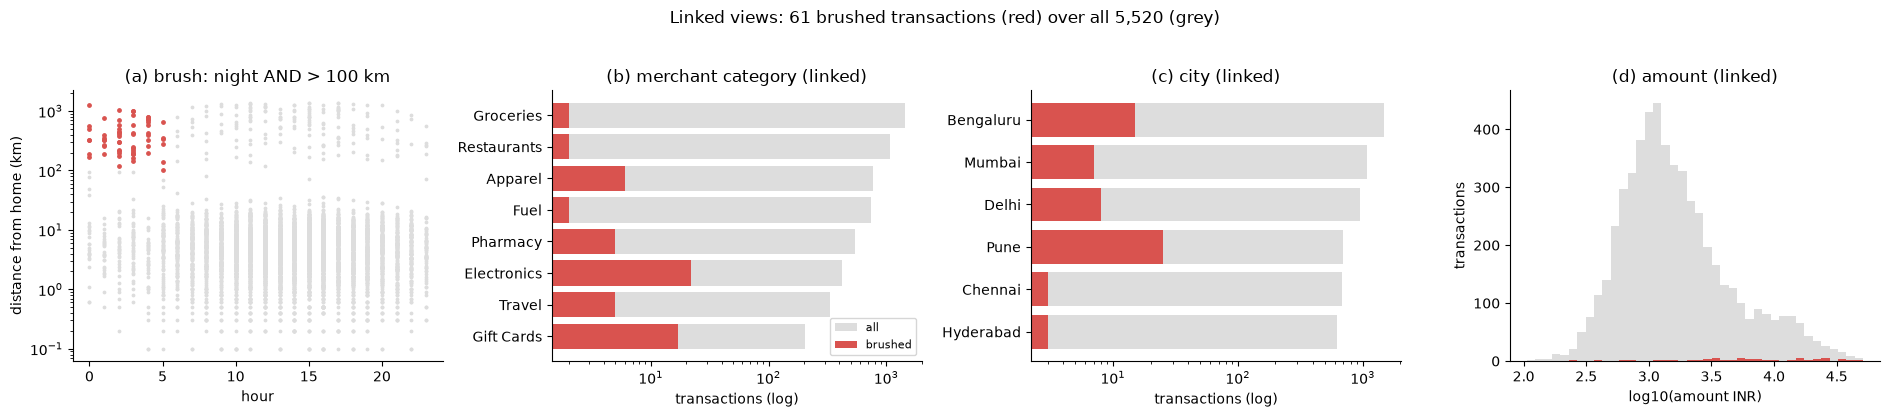

Brushed transactions       : 61
Fraud rate inside brush    : 86.9%  vs overall 2.2%  (40x lift)
Share of ALL fraud captured: 44.2%  (53 of 120)

Where the fraud OUTSIDE the brush is (top cities / categories):
city
Pune         27
Bengaluru    10
Mumbai        9
merchant_category
Electronics    26
Gift Cards     24
Travel         10


In [3]:
# TODO 1
brush = (tx.night) & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2
# (a) hour vs distance - the view where the brush is "drawn"
axes[0].scatter(tx.hour[~brush], tx.distance_from_home_km[~brush], s=3, c="#dddddd")
axes[0].scatter(tx.hour[brush], tx.distance_from_home_km[brush], s=6, c="#D9534F")
axes[0].set_yscale("log"); axes[0].set_xlabel("hour"); axes[0].set_ylabel("distance from home (km)")
axes[0].set_title("(a) brush: night AND > 100 km")
# (b) merchant category and (c) city - linked bar charts
for ax, col, t in zip(axes[1:3], ["merchant_category", "city"], ["(b) merchant category", "(c) city"]):
    allc = tx[col].value_counts()
    bc = tx.loc[brush, col].value_counts().reindex(allc.index, fill_value=0)
    ax.barh(allc.index, allc.values, color="#dddddd", label="all")
    ax.barh(bc.index, bc.values, color="#D9534F", label="brushed")
    ax.invert_yaxis(); ax.set_xscale("log"); ax.set_xlabel("transactions (log)"); ax.set_title(f"{t} (linked)")
axes[1].legend(fontsize=8)
# (d) amount histogram on log10 scale
bins = np.linspace(np.log10(tx.amount_inr).min(), np.log10(tx.amount_inr).max(), 41)
axes[3].hist(np.log10(tx.amount_inr), bins=bins, color="#dddddd")
axes[3].hist(np.log10(tx.amount_inr[brush]), bins=bins, color="#D9534F")
axes[3].set_xlabel("log10(amount INR)"); axes[3].set_ylabel("transactions"); axes[3].set_title("(d) amount (linked)")
fig.suptitle(f"Linked views: {brush.sum()} brushed transactions (red) over all {len(tx):,} (grey)", y=1.03)
plt.tight_layout(); plt.show()

# TODO 3
n_brush = int(brush.sum())
rate_in, rate_all = tx.is_fraud[brush].mean(), tx.is_fraud.mean()
captured = tx.is_fraud[brush].sum() / tx.is_fraud.sum()
print(f"Brushed transactions       : {n_brush}")
print(f"Fraud rate inside brush    : {rate_in:.1%}  vs overall {rate_all:.1%}  ({rate_in/rate_all:.0f}x lift)")
print(f"Share of ALL fraud captured: {captured:.1%}  ({tx.is_fraud[brush].sum()} of {tx.is_fraud.sum()})")
missed = tx[(tx.is_fraud == 1) & ~brush]
print("\nWhere the fraud OUTSIDE the brush is (top cities / categories):")
print(missed.city.value_counts().head(3).to_string()); print(missed.merchant_category.value_counts().head(3).to_string())

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_ The rule is very precise but covers only part of the fraud. 53 of the 61 brushed transactions are fraud (86.9% vs 2.2% overall, roughly 40× lift), but that is only **44% of all fraud (53 of 120)**. As a rule of thumb, "night-time and far from home" gives high precision and low recall. If investigators relied on it alone, they would miss more than half of the frauds. These are mostly daytime or close-to-home cases that look normal on those two features. The **merchant-category view** and the **city view** pointed to the rest. In the category bars, the red brush is almost entirely Electronics and Gift Cards. In the city bars, Pune stands out. The fraud outside the brush is concentrated in the same places (Pune 27, Electronics 26, Gift Cards 24). So the next rule should use merchant category and city as well as time and distance.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1
times = []
for _ in range(5):
    t0 = time.perf_counter()
    _ = big[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]
    times.append(time.perf_counter() - t0)
best_s = min(times)

# TODO 2
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / (best_s / len(big))

# TODO 3
t_50m = 50_000_000 * per_item_us / 1e6
skip_pct = max(0.0, (1 - max_rows / 50_000_000) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 55.6 ms -> 0.0553 us/row -> max 1,808,442 rows in 0.1 s
50M rows -> 2.76 s; must skip 96.4% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_ One option is **aggregation**: pre-compute binned counts, for example a cube of score-bin × amount-bin × city × day, and let the slider query the bins instead of the raw rows. That is a few thousand cells instead of 50 million, so each slider move takes well under 0.1 s. (Random **sampling** is another reduce option.) The cost is item-level detail. The analyst sees counts and rates per bin rather than individual transactions, so they can't hover on a single suspicious payment, and a rare fraud pattern inside a bin is averaged away. Thresholds also snap to the bin edges. A common compromise is to show the aggregate while the slider is being dragged, then fetch the full detail rows once it is released.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

,threshold,alerts,TP,FP,FN,precision,recall,F1
0,0.05,2012,114,1898,6,0.057,0.950,0.107
1,0.10,1167,111,1056,9,0.095,0.925,0.172
2,0.15,786,110,676,10,0.140,0.917,0.243
3,0.20,596,106,490,14,0.178,0.883,0.296
4,0.25,471,105,366,15,0.223,0.875,0.355
5,0.30,401,104,297,16,0.259,0.867,0.399
6,0.35,355,104,251,16,0.293,0.867,0.438
7,0.40,319,104,215,16,0.326,0.867,0.474
8,0.45,283,104,179,16,0.367,0.867,0.516
9,0.50,260,101,159,19,0.388,0.842,0.532


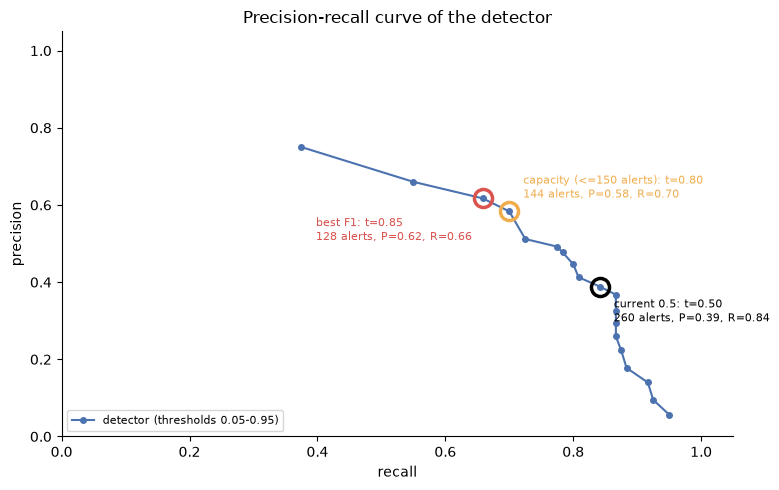

Current t=0.50: 260 alerts/month, P=0.39, R=0.84, F1=0.53
Best-F1 t=0.85: 128 alerts, P=0.62, R=0.66, F1=0.64
RECOMMENDATION: set the threshold to 0.80 -> 144 alerts/month (within the 150 capacity), catching 70% of fraud at 58% precision.


In [5]:
rows = []
# TODO 1
for th in np.round(np.arange(0.05, 1.0, 0.05), 2):
    flag = tx.detector_score >= th
    tp = int((flag & (tx.is_fraud == 1)).sum())
    fp = int((flag & (tx.is_fraud == 0)).sum())
    fn = int((~flag & (tx.is_fraud == 1)).sum())
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    rows.append(dict(threshold=th, alerts=tp + fp, TP=tp, FP=fp, FN=fn, precision=p, recall=r, F1=f1))

pr = pd.DataFrame(rows)

# TODO 2
CAPACITY = 150
feasible = pr[pr.alerts <= CAPACITY]
capacity_choice = feasible.sort_values(["recall", "precision"], ascending=False).iloc[0]
best_f1 = pr.loc[pr.F1.idxmax()]
current = pr.loc[np.isclose(pr.threshold, 0.5)].iloc[0]
display(pr.round(3))

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, "o-", color="#4C72B0", ms=4, label="detector (thresholds 0.05-0.95)")
for row, col, name, off in [(current, "black", "current 0.5", (10, -25)),
                            (capacity_choice, "#f0ad4e", "capacity (<=150 alerts)", (10, 10)),
                            (best_f1, "#D9534F", "best F1", (-120, -30))]:
    ax.plot(row.recall, row.precision, "o", ms=13, mfc="none", mec=col, mew=2.5)
    ax.annotate(f"{name}: t={row.threshold:.2f}\n{int(row.alerts)} alerts, P={row.precision:.2f}, R={row.recall:.2f}",
                (row.recall, row.precision), xytext=off, textcoords="offset points", fontsize=8, color=col)
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1.05); ax.set_ylim(0, 1.05)
ax.set_title("Precision-recall curve of the detector"); ax.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

# TODO 4
print(f"Current t=0.50: {int(current.alerts)} alerts/month, P={current.precision:.2f}, R={current.recall:.2f}, F1={current.F1:.2f}")
print(f"Best-F1 t={best_f1.threshold:.2f}: {int(best_f1.alerts)} alerts, P={best_f1.precision:.2f}, R={best_f1.recall:.2f}, F1={best_f1.F1:.2f}")
print(f"RECOMMENDATION: set the threshold to {capacity_choice.threshold:.2f} -> {int(capacity_choice.alerts)} alerts/month "
      f"(within the {CAPACITY} capacity), catching {capacity_choice.recall:.0%} of fraud at {capacity_choice.precision:.0%} precision.")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_ The **Head of Fraud Ops** should decide. The model can only produce the precision–recall trade-off. It doesn't know the business constraints and costs: that the team can review only 150 alerts, that a missed fraud costs far more than a wasted review, or that a ring is currently active. In our data, the best-F1 point (t = 0.85, 128 alerts, F1 0.637) and the capacity choice (t = 0.80, 144 alerts, F1 0.636) are almost tied on F1. But 0.80 catches 5 more frauds (recall 70% vs 66%) and still fits the capacity. F1 can't express that kind of judgement because it weights precision and recall equally. Visual analytics keeps a human in the loop because the human **steers the model parameter** while watching the PR curve update. They bring domain knowledge the model doesn't have, and their confirm/reject decisions become labels that improve the model (Slides 35–37). The automation scales the search, and the human stays accountable for the decision.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

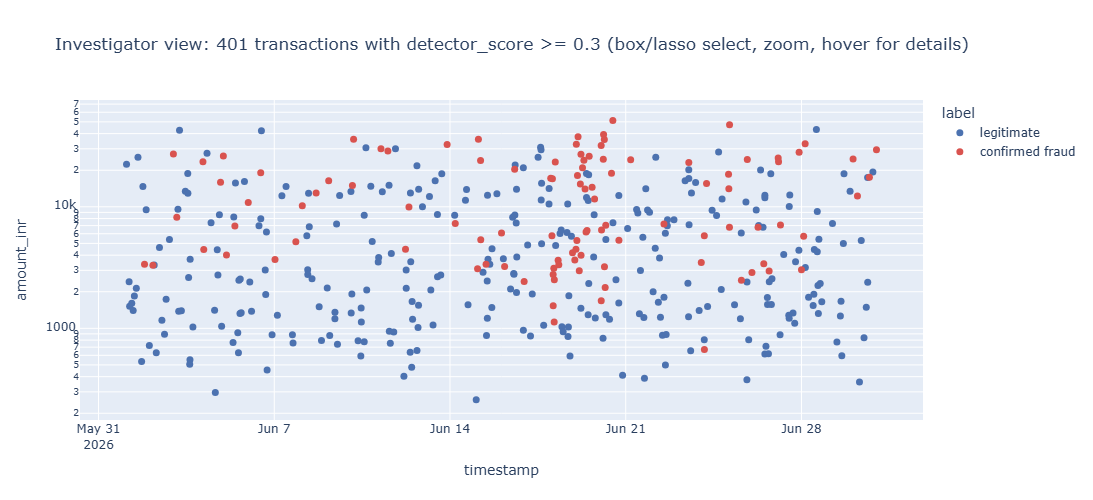

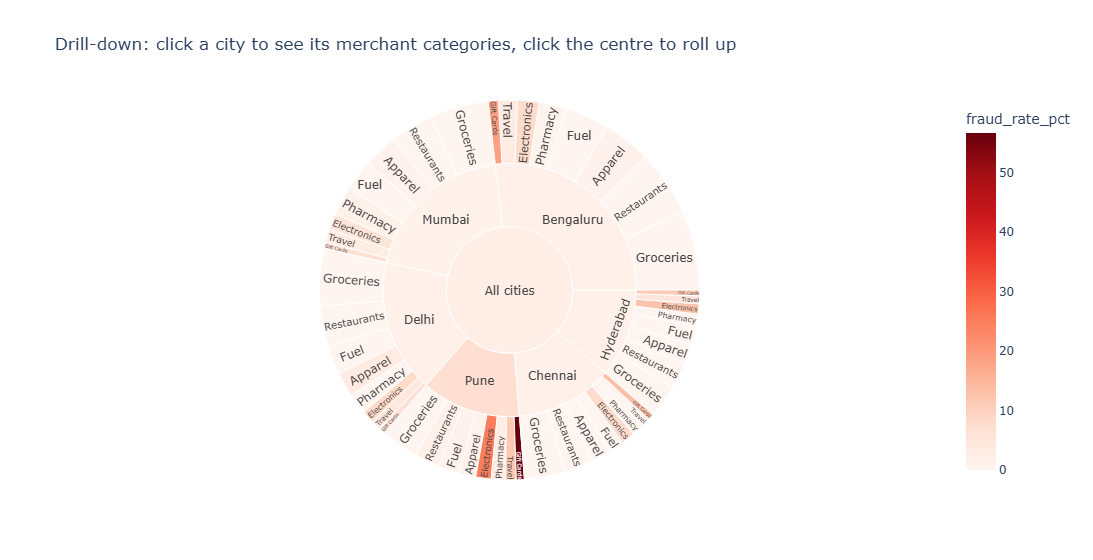

In [6]:
# TODO 1
flagged = tx[tx.detector_score >= 0.3]
fig = px.scatter(flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
                 color_discrete_map={"legitimate": "#4C72B0", "confirmed fraud": "#D9534F"},
                 hover_name="txn_id",
                 hover_data={"customer_id": True, "city": True, "merchant_category": True,
                             "distance_from_home_km": ":.0f", "detector_score": ":.3f",
                             "label": False, "timestamp": "|%d %b %H:%M", "amount_inr": ":,.0f"},
                 title=f"Investigator view: {len(flagged)} transactions with detector_score >= 0.3 "
                       "(box/lasso select, zoom, hover for details)", height=500)
fig.update_traces(marker_size=7, unselected_marker_opacity=0.15)
fig.update_layout(dragmode="select")
fig.show()

# TODO 2
agg = tx.groupby(["city", "merchant_category"]).agg(transactions=("txn_id", "size"),
                                                     fraud=("is_fraud", "sum")).reset_index()
agg["fraud_rate_pct"] = agg.fraud / agg.transactions * 100
fig = px.sunburst(agg, path=[px.Constant("All cities"), "city", "merchant_category"], values="transactions",
                  color="fraud_rate_pct", color_continuous_scale="Reds",
                  hover_data={"fraud": True, "fraud_rate_pct": ":.1f"},
                  title="Drill-down: click a city to see its merchant categories, click the centre to roll up",
                  height=560)
fig.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_ A tooltip shows one item and disappears when the cursor moves. To understand 400 cases, the investigator would have to hover 400 times and hold all the details in their head to compare them. That puts the work on memory instead of the eyes, it is slow, and patterns such as "most of these are Pune electronics" never appear because no two cases are visible together. Tooltips are for details-on-demand *after* an overview, not instead of one. The **sunburst** (and the reordered city × day heatmap from Task 1) fixes this. It aggregates all flagged cases by city → merchant category and colours each segment by fraud rate, so the whole picture is visible at once. The investigator can then drill down and hover only on the few cases that matter.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

H1: a fraud ring operated in Pune on days 18-20 (fraud rate there is much higher than in the same city on other days AND other cities on those days).
is_fraud     0   1
row_0             
False     5333  80
True        67  40

Fraud rate inside window: 37.4% (40/107)  vs outside: 1.5%  -> chi2 = 619.3, p = 1.1e-136
(a) Pune on OTHER days      : 1.9%  (n=593)
(b) OTHER cities on days 18-20: 0.4%  (n=457)
    everything else           : 1.5%


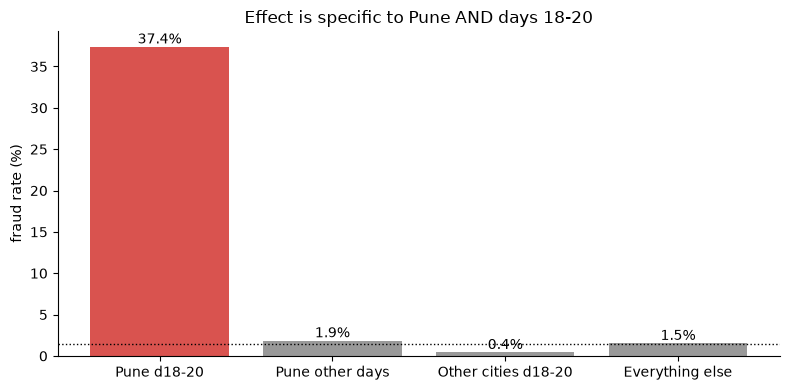

VERDICT: SUPPORTED - fraud concentrated in Pune on days 18-20 only (37% vs 1.9% same city other days and 0.4% other cities same days; p = 1.1e-136).


In [7]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask 
top_city = top_cells.city.iloc[0]
hot_days = sorted(top_cells[top_cells.city == top_city].head(3).day)
D0, D1 = min(hot_days), max(hot_days)
print(f"H1: a fraud ring operated in {top_city} on days {D0}-{D1} "
      f"(fraud rate there is much higher than in the same city on other days AND other cities on those days).")
in_city, in_days = tx.city == top_city, tx.day.between(D0, D1)
in_window = in_city & in_days

# TODO 2
table = pd.crosstab(in_window, tx.is_fraud)
chi2, pval, dof, _ = chi2_contingency(table)
r_in, r_out = tx.is_fraud[in_window].mean(), tx.is_fraud[~in_window].mean()
print(table)
print(f"\nFraud rate inside window: {r_in:.1%} ({tx.is_fraud[in_window].sum()}/{in_window.sum()})  "
      f"vs outside: {r_out:.1%}  -> chi2 = {chi2:.1f}, p = {pval:.1e}")

# TODO 3: counter-example searches
same_city_other = in_city & ~in_days
other_city_same = ~in_city & in_days
rest = ~in_city & ~in_days
r_a, r_b, r_rest = tx.is_fraud[same_city_other].mean(), tx.is_fraud[other_city_same].mean(), tx.is_fraud[rest].mean()
print(f"(a) {top_city} on OTHER days      : {r_a:.1%}  (n={same_city_other.sum()})")
print(f"(b) OTHER cities on days {D0}-{D1}: {r_b:.1%}  (n={other_city_same.sum()})")
print(f"    everything else           : {r_rest:.1%}")

# TODO 4
fig, ax = plt.subplots(figsize=(8, 4))
grp = {f"{top_city} d{D0}-{D1}": r_in, f"{top_city} other days": r_a,
       f"Other cities d{D0}-{D1}": r_b, "Everything else": r_rest}
bars = ax.bar(grp.keys(), np.array(list(grp.values())) * 100, color=["#D9534F", "#999999", "#999999", "#999999"])
for b, v in zip(bars, grp.values()):
    ax.text(b.get_x() + b.get_width() / 2, v * 100, f"{v:.1%}", ha="center", va="bottom")
ax.axhline(r_out * 100, color="black", ls=":", lw=1); ax.set_ylabel("fraud rate (%)")
ax.set_title(f"Effect is specific to {top_city} AND days {D0}-{D1}")
plt.tight_layout(); plt.show()

# TODO 5
supported = pval < 0.01 and r_in > 3 * max(r_a, r_b)
print("VERDICT:", f"SUPPORTED - fraud concentrated in {top_city} on days {D0}-{D1} only "
      f"({r_in:.0%} vs {r_a:.1%} same city other days and {r_b:.1%} other cities same days; p = {pval:.1e})."
      if supported else "NOT SUPPORTED - the spike is explained by the city or the days in general.")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_ Both searches could have killed it, but the most important one is **(a) Pune on other days**. If Pune's fraud rate on the other 27 days had also been high (say 20–30%), the spike would just be "Pune is always a high-fraud city" (a weak local merchant base, a compromised acquirer, or a known high-risk area). In that case there would be no special event on days 18–20 and nothing ring-like to escalate. It came out at **1.9%**, close to the 1.5% baseline, so Pune is normal apart from those three days. Search **(b), other cities on days 18–20**, tests the other alternative: a system-wide cause such as a detector or labelling glitch, a festival or sale period, or a nationwide card breach. That came out at **0.4%**, so those days were normal everywhere except Pune. With both searches failing to find a counter-example, plus 37.4% vs 1.5% and p ≈ 1e-136, the effect is specific to *Pune and those days together*, which is what a localized ring looks like.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

To the Head of Fraud Ops: last month we had 120 confirmed frauds in 5,520 transactions (2.2%), and a third of them (40) came from a single localized burst in **Pune on days 18–20**. Fraud there ran at 37% against a 1.5% baseline (p ≈ 1e-136), while Pune on other days and other cities on those days were both normal, which points strongly to a fraud ring. I recommend moving the alert threshold from **0.5 to 0.80**. That cuts alerts from 260 to **144 a month**, which fits the team's 150 capacity, raises precision from 39% to 58%, and still catches 70% of fraud. It is essentially tied with the best-F1 point (0.85) but catches more fraud, and this trade-off should stay your decision, made on the PR curve, rather than an automatic F1 optimum. The first tool to build is the **overview city × day heatmap with click-to-drill-down into the flagged cases**: overview first, then zoom and filter, then details-on-demand. It is what exposed the Pune ring, which a score-sorted alert list hid, and on 50M rows it should run on pre-aggregated data so every interaction stays within the 0.1 s budget. Finally, we should add the **analyst-feedback loop** (Slide 51): every alert an investigator confirms or rejects, plus every missed fraud found later, should go back as a label to retrain the detector. Next month's model would then learn features such as category, city and time-of-day clusters that the current score is missing.